# SPK Prioritas Restocking Bahan Baku - UMKM Jasa Ayah (AHP-SAW)

```
SPK PRIORITAS RESTOCKING BAHAN BAKU - UMKM JASA AYAH (CABANG JL. GARBIS)
Pipeline: Pre-processing -> Data Cleaning -> EDA -> Penetapan Kriteria -> Matriks Keputusan -> Normalisasi -> AHP -> SAW -> Evaluasi

Library : pandas, numpy, openpyxl, matplotlib, scipy
Install : pip install pandas numpy openpyxl matplotlib scipy

## Impor library

In [1]:
import os
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## Bagian 0. KONFIGURASI

In [2]:
# --- 0.1 File input (urut kronologis)
FILES = {
    "MEI":  "5. SO JA GARBIS MEI 2026.xlsx",
    "JUNI": "6. SO JA GARBIS JUNI 2026.xlsx",
    "JULI": "7. SO JA GARBIS JULI 2026-2.xlsx",
}
SHEET_STOK = "Data Stok&Order"
SHEET_RUPIAH = "Dalam Rupiah"
SHEET_RESEP = "Resep"
OUTPUT_DIR = "output_ahp_saw"

# --- 0.2 Alternatif
ALTERNATIF = {
    "A1": ("Ayam",        ["Ayam Cut 10"]),
    "A2": ("Telur",       ["Telur Ayam"]),
    "A3": ("Beras",       ["Beras C"]),
    "A4": ("Minyak Goreng", ["Minyak Goreng"]),
    "A5": ("Cabai",       ["cabe rawit merah"]),
    "A6": ("Teh Tarik",   ["Teh A"]),
}

# --- 0.3 Kriteria & jenis (sesuai Tabel 4.3)
KRITERIA = {
    "C1": ("Tingkat kepentingan bahan", "benefit"),
    "C2": ("Nilai pemakaian harian (Rp/hari)", "benefit"),
    "C3": ("Hari cakupan stok", "cost"),
    "C4": ("Lead time pemasok (hari)", "benefit"),
    "C5": ("Daya tahan simpan (hari)", "cost"),
}

# --- 0.4 Input hasil WAWANCARA (Lampiran A: Tabel A.1 & A.2)
SKOR_C1 = {"A1": 4, "A2": 5, "A3": 5, "A4": 4, "A5": 2, "A6": 5}                 # skor 1-5
LEADTIME_C4 = {"A1": 1, "A2": 1, "A3": 1, "A4": 1, "A5": 1, "A6": 1}              # hari
SHELFLIFE_C5 = {"A1": 5, "A2": 30, "A3": 30, "A4": 30, "A5": 3, "A6": 30}       # hari

# --- 0.5 Input KUESIONER AHP (Lampiran B)
RESPONDEN_AHP = {
    "Pemilik": [
        ("C1", "C2", 1, "sama"),
        ("C1", "C3", 8, "kiri"),
        ("C1", "C4", 1, "sama"),
        ("C1", "C5", 9, "kiri"),
        ("C2", "C3", 7, "kiri"),
        ("C2", "C4", 1, "sama"),
        ("C2", "C5", 8, "kiri"),
        ("C3", "C4", 6, "kanan"),
        ("C3", "C5", 1, "sama"),
        ("C4", "C5", 7, "kiri"),
    ],
}
RI = {1: 0, 2: 0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}
CR_MAKS = 0.10

# --- 0.6 Urutan prioritas versi pemilik (Lampiran C), 1 = paling didahulukan
URUTAN_PEMILIK = {"A1": 3, "A2": 2, "A3": 1, "A4": 5, "A5": 6, "A6": 4}

# --- 0.7 Parameter lain
INPUT_FINAL = True
TANGGAL_STOK_AKHIR = None  # None = otomatis tanggal valid terakhir
NEGATIF_JADI_NAN = True    # penggunaan negatif dianggap galat pencatatan -> NaN
ABAIKAN_HARI_HABIS_DI_RATA2 = False  # True: hari stok nol tidak ikut rata-rata pemakaian
AMBANG_KRITIS_HARI = 1.0   # triangulasi: stok < 1 hari pemakaian dianggap kritis
C3_METODE = "akhir"       # "akhir" = stok tgl terakhir / rata2 pakai; "rata2" = rata-rata hari cakupan seluruh periode
PROPORSI_MIN_TERISI = 0.10 # tanggal dianggap 'belum diisi' bila <10% bahan punya SO gudang > 0

os.makedirs(OUTPUT_DIR, exist_ok=True)
LOG = []   # catatan seluruh langkah cleaning


def log(tahap, keterangan, jumlah=None):
    LOG.append({"tahap": tahap, "keterangan": keterangan, "jumlah": jumlah})
    print(f"[{tahap}] {keterangan}" + (f" -> {jumlah}" if jumlah is not None else ""))


def norm(s):
    return str(s).strip().lower()

## Bagian 1. PRE-PROCESSING  (baca & gabung 3 berkas bulanan)

In [3]:
# Struktur kedua sheet: tiap tanggal = blok 8 kolom
# [masuk, sisa_bag, sisa_open, waste, so_gudang, pakai, harga/total, order]
FIELD = ["masuk", "sisa_bag", "sisa_open", "waste", "so_gudang", "pakai", "harga", "order"]
BUKAN_BAHAN = {"", "0", "#ref!", "bar", "kasir", "kitchen", "juicer", "sushi", "all", "nama bahan", "none"}


def baca_sheet(path, sheet, kol_nama, baris_tanggal, awalan):
    wb = openpyxl.load_workbook(path, data_only=True, read_only=True)
    rows = list(wb[sheet].iter_rows(values_only=True))
    wb.close()
    tgl_kolom = [(i, c) for i, c in enumerate(rows[baris_tanggal]) if hasattr(c, "year")]
    out = []
    for r in rows[baris_tanggal + 2:]:
        nama = r[kol_nama]
        if nama is None or norm(nama) in BUKAN_BAHAN or norm(nama).startswith("[prod]"):
            continue
        for i, d in tgl_kolom:
            blok = r[i:i + 8]
            rec = {"bahan": str(nama).strip(), "bahan_key": norm(nama), "tgl": pd.Timestamp(d)}
            rec.update({f"{awalan}{k}": v for k, v in zip(FIELD, blok)})
            out.append(rec)
    return pd.DataFrame(out)


def gabung_berkas():
    frames = []
    for urut, (bulan, path) in enumerate(FILES.items()):
        if not os.path.exists(path):
            raise FileNotFoundError(f"File {path} tidak ditemukan (cek FILES / folder kerja).")
        stok = baca_sheet(path, SHEET_STOK, 1, 0, "")
        rp = baca_sheet(path, SHEET_RUPIAH, 0, 1, "rp_")
        rp = rp[["bahan_key", "tgl", "rp_masuk", "rp_so_gudang", "rp_pakai", "rp_harga"]]
        stok = stok.drop_duplicates(["bahan_key", "tgl"])   # nama kembar dalam 1 file: ambil yg pertama
        rp = rp.drop_duplicates(["bahan_key", "tgl"])
        m = stok.merge(rp, on=["bahan_key", "tgl"], how="left")
        m["file"], m["urut_file"] = bulan, urut
        frames.append(m)
        log("PRE", f"Berkas {bulan} dibaca: {path}", len(m))
    return pd.concat(frames, ignore_index=True)


raw = gabung_berkas()
log("PRE", "Total baris gabungan (bahan x tanggal x berkas)", len(raw))
log("PRE", "Catatan: penggabungan memakai NAMA bahan (urutan baris tiap bulan berbeda).")

[PRE] Berkas MEI dibaca: 5. SO JA GARBIS MEI 2026.xlsx -> 4433
[PRE] Berkas JUNI dibaca: 6. SO JA GARBIS JUNI 2026.xlsx -> 4371
[PRE] Berkas JULI dibaca: 7. SO JA GARBIS JULI 2026-2.xlsx -> 4433
[PRE] Total baris gabungan (bahan x tanggal x berkas) -> 13237
[PRE] Catatan: penggabungan memakai NAMA bahan (urutan baris tiap bulan berbeda).


## Bagian 2. DATA CLEANING

In [4]:
num_cols = ["masuk", "sisa_bag", "sisa_open", "waste", "so_gudang", "pakai",
            "rp_masuk", "rp_so_gudang", "rp_pakai", "rp_harga"]
for c in num_cols:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

In [5]:
# 2.1 Tanggal 'kosong' (placeholder), mis. 1 Juli di berkas Juni (stok belum diisi).
#     Dideteksi dari proporsi baris bahan yang SO gudangnya terisi (> 0).
raw["so_terisi"] = raw["so_gudang"].fillna(0) > 0
prop = raw.groupby(["file", "tgl"])["so_terisi"].mean()
tgl_kosong = prop[prop < PROPORSI_MIN_TERISI].index.tolist()
for f, t in tgl_kosong:
    log("CLEAN", f"Tanggal {t.date()} di berkas {f} belum terisi (hanya {prop[(f, t)]:.1%} bahan punya SO gudang) -> dibuang")
raw = raw[~raw.set_index(["file", "tgl"]).index.isin(tgl_kosong)].copy()

[CLEAN] Tanggal 2026-07-01 di berkas JUNI belum terisi (hanya 0.7% bahan punya SO gudang) -> dibuang


In [6]:
# 2.2 Tanggal ganda antar-berkas -> pakai berkas paling baru
dup = raw.duplicated(["bahan_key", "tgl"], keep="last")
if dup.any():
    tg = sorted(raw.loc[raw.duplicated(["tgl"], keep=False), "tgl"].dt.date.unique())
    log("CLEAN", f"Tanggal ganda antar-berkas {tg} -> versi berkas terbaru dipakai", int(dup.sum()))
raw = raw[~dup].sort_values(["bahan_key", "tgl"]).reset_index(drop=True)

In [7]:
# 2.3 Kelengkapan kalender
semua = pd.date_range(raw["tgl"].min(), raw["tgl"].max(), freq="D")
hilang = semua.difference(raw["tgl"].unique())
log("CLEAN", f"Periode {raw['tgl'].min().date()} s.d. {raw['tgl'].max().date()} "
             f"({len(semua)} hari kalender, {raw['tgl'].nunique()} hari tercatat)")
if len(hilang):
    log("CLEAN", f"Tanggal tidak ada datanya: {[d.date() for d in hilang]}")

[CLEAN] Periode 2026-05-01 s.d. 2026-07-31 (92 hari kalender, 92 hari tercatat)


In [8]:
# 2.4 Saring alternatif (bahan kritis) & cek nama ketemu di semua berkas
peta = {norm(b): (kode, nm) for kode, (nm, lst) in ALTERNATIF.items() for b in lst}
df = raw[raw["bahan_key"].isin(peta)].copy()
df["alt"] = df["bahan_key"].map(lambda k: peta[k][0])
df["alt_nama"] = df["bahan_key"].map(lambda k: peta[k][1])
for b in peta:
    for f in FILES:
        if not ((df["bahan_key"] == b) & (df["file"] == f)).any():
            log("CLEAN", f"PERINGATAN: bahan '{b}' tidak ditemukan di berkas {f} (cek ejaan nama)")
log("CLEAN", f"Baris setelah disaring {len(ALTERNATIF)} alternatif", len(df))

[CLEAN] Baris setelah disaring 6 alternatif -> 552


In [9]:
# 2.5 Nilai hilang: kosong pada masuk/waste/sisa = tidak ada kejadian -> 0
for c in ["masuk", "sisa_bag", "sisa_open", "waste", "rp_masuk"]:
    n = int(df[c].isna().sum())
    df[c] = df[c].fillna(0)
    log("CLEAN", f"Nilai kosong kolom '{c}' diisi 0", n)
n_pakai_na = int(df[["pakai", "rp_pakai", "rp_so_gudang"]].isna().any(axis=1).sum())
log("CLEAN", "Baris dengan pakai/Rupiah kosong (tidak diisi 0, dibiarkan NaN)", n_pakai_na)

[CLEAN] Nilai kosong kolom 'masuk' diisi 0 -> 289
[CLEAN] Nilai kosong kolom 'sisa_bag' diisi 0 -> 191
[CLEAN] Nilai kosong kolom 'sisa_open' diisi 0 -> 100
[CLEAN] Nilai kosong kolom 'waste' diisi 0 -> 544
[CLEAN] Nilai kosong kolom 'rp_masuk' diisi 0 -> 0
[CLEAN] Baris dengan pakai/Rupiah kosong (tidak diisi 0, dibiarkan NaN) -> 0


In [10]:
# 2.6 Galat pencatatan: penggunaan negatif
neg = (df["pakai"] < 0) | (df["rp_pakai"] < 0)
df["anomali_negatif"] = neg
log("CLEAN", "Penggunaan NEGATIF terdeteksi (galat pencatatan, biasanya di hari barang masuk)", int(neg.sum()))
if NEGATIF_JADI_NAN:
    df.loc[neg, ["pakai", "rp_pakai"]] = np.nan
    log("CLEAN", "Nilai negatif diubah NaN (tidak ikut rata-rata)")

[CLEAN] Penggunaan NEGATIF terdeteksi (galat pencatatan, biasanya di hari barang masuk) -> 3
[CLEAN] Nilai negatif diubah NaN (tidak ikut rata-rata)


In [11]:
# 2.7 Hari stok habis (SO gudang = 0) -> pemakaian bisa lebih rendah dari kebutuhan nyata
df["hari_habis"] = df["so_gudang"] == 0
log("CLEAN", "Hari stok habis (SO gudang = 0) ditandai", int(df["hari_habis"].sum()))
if ABAIKAN_HARI_HABIS_DI_RATA2:
    df.loc[df["hari_habis"], ["pakai", "rp_pakai"]] = np.nan

[CLEAN] Hari stok habis (SO gudang = 0) ditandai -> 8


In [12]:
# 2.8 Verifikasi pergerakan stok (Rupiah): pakai_t = SO_(t-1) + masuk_t - SO_t
df = df.sort_values(["bahan_key", "tgl"])
prev = df.groupby("bahan_key")["rp_so_gudang"].shift(1)
df["selisih_rekon"] = prev + df["rp_masuk"] - df["rp_so_gudang"] - df["rp_pakai"]
tdk_cocok = df["selisih_rekon"].abs() > 1
log("CLEAN", "Hari dengan pergerakan stok tidak cocok (|selisih| > Rp1) - tinjau manual", int(tdk_cocok.sum()))

[CLEAN] Hari dengan pergerakan stok tidak cocok (|selisih| > Rp1) - tinjau manual -> 6


In [13]:
# 2.9 Satuan: seluruh perbandingan antarbahan memakai Rupiah (kolom rp_*);
#     kolom satuan asli (gram/ml/pcs) hanya dipakai untuk EDA per bahan.
df["tgl"] = pd.to_datetime(df["tgl"])
df.to_csv(f"{OUTPUT_DIR}/data_bersih_detail.csv", index=False)

# Data harian per ALTERNATIF (jumlahkan jika >1 baris bahan)
harian = (df.groupby(["alt", "alt_nama", "tgl"])
            .agg(pakai_rp=("rp_pakai", lambda s: s.sum(min_count=1)),
                 stok_rp=("rp_so_gudang", lambda s: s.sum(min_count=1)),
                 masuk_rp=("rp_masuk", "sum"),
                 hari_habis=("hari_habis", "max"),
                 anomali=("anomali_negatif", "max"))
            .reset_index())

## Bagian 3. EDA


EDA
alt      alt_nama  n_hari  rata2_pakai_rp  median_pakai_rp  std_pakai_rp  min_pakai_rp  maks_pakai_rp  hari_pakai_nol  hari_habis  anomali_negatif  rata2_stok_rp  CV_pakai  share_pakai_%
 A1          Ayam      92    133,000.0000     132,000.0000   84,691.5541        0.0000   528,000.0000              11           4                0   329,923.9130    0.6368        17.1844
 A2         Telur      92    223,331.9565     197,600.0000  101,892.7968    2,940.0000   522,500.0000               0           0                0   173,413.0435    0.4562        28.8558
 A3         Beras      92    270,366.7783     265,858.3400  134,853.9558        0.0000   567,590.4000               4           3                0   916,058.2670    0.4988        34.9330
 A4 Minyak Goreng      92    106,383.6593      97,625.0000   53,149.1055        0.0000   272,710.7778               1           0                1 1,034,129.2035    0.4996        13.7454
 A5         Cabai      92      8,594.4444       8,150.0000  

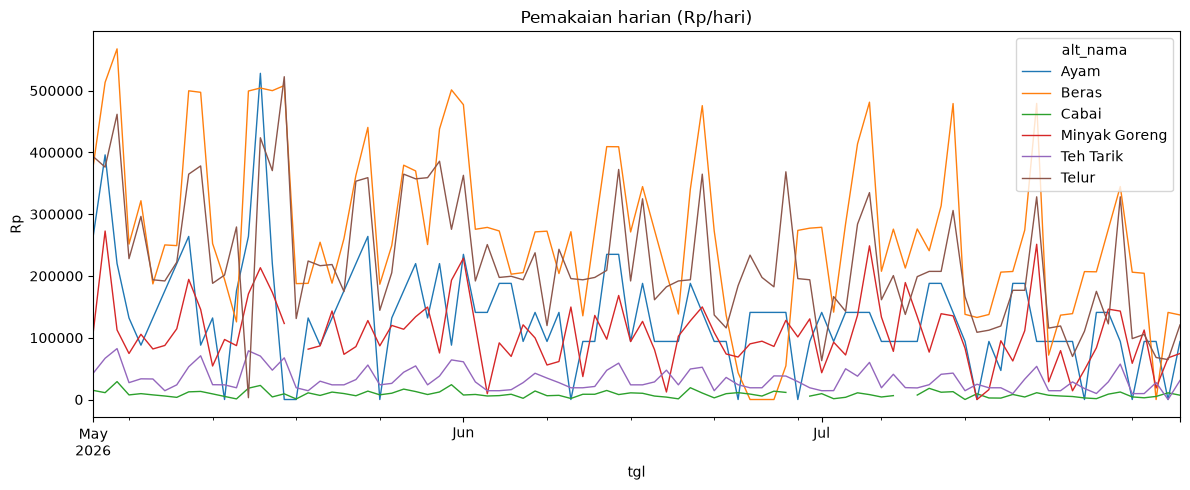

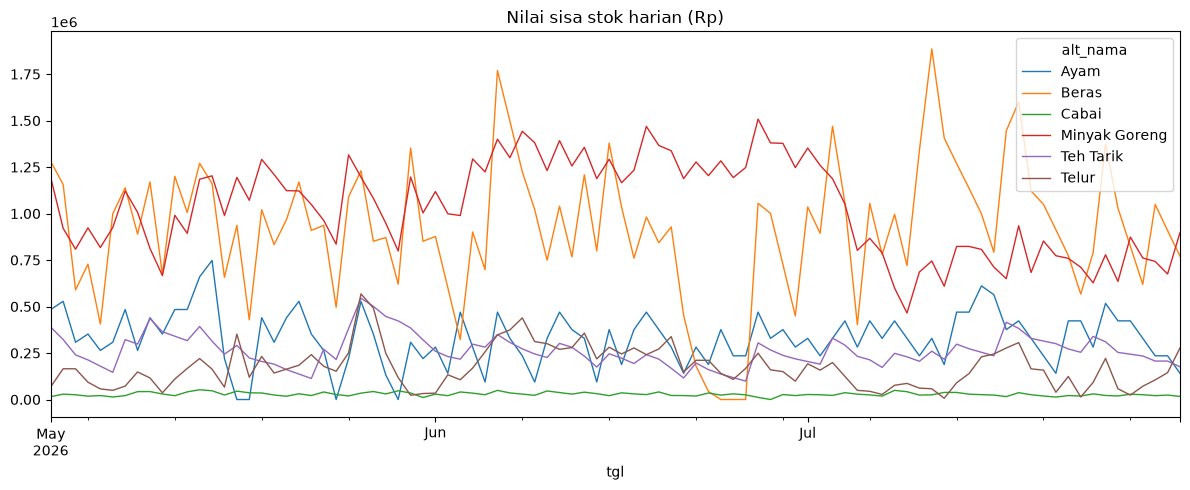

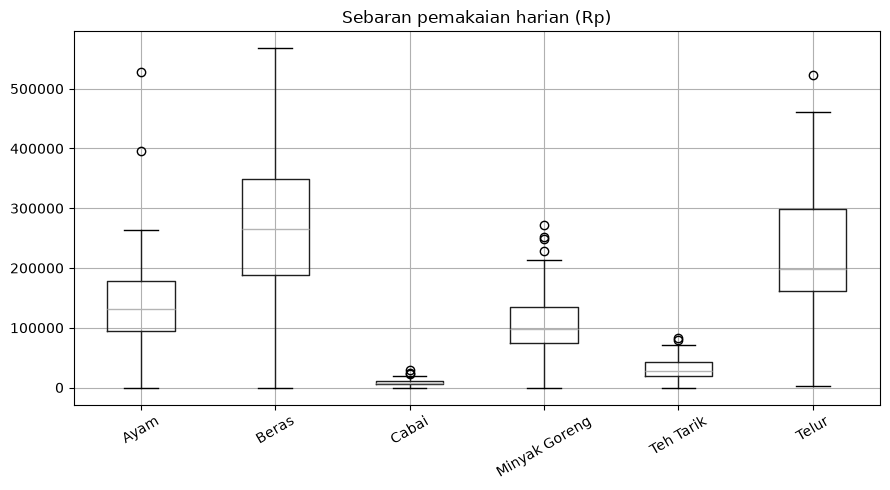

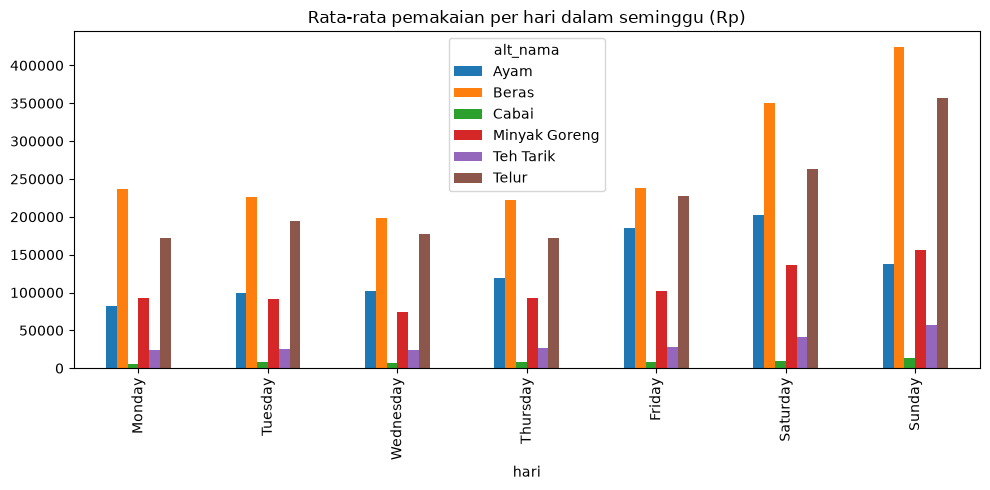

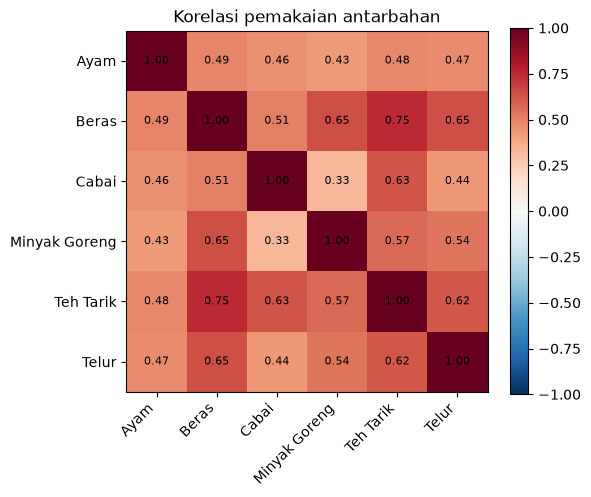

In [14]:
print("\n" + "=" * 70 + "\nEDA\n" + "=" * 70)
eda = (harian.groupby(["alt", "alt_nama"])
       .agg(n_hari=("tgl", "nunique"),
            rata2_pakai_rp=("pakai_rp", "mean"), median_pakai_rp=("pakai_rp", "median"),
            std_pakai_rp=("pakai_rp", "std"), min_pakai_rp=("pakai_rp", "min"),
            maks_pakai_rp=("pakai_rp", "max"),
            hari_pakai_nol=("pakai_rp", lambda s: int((s == 0).sum())),
            hari_habis=("hari_habis", "sum"), anomali_negatif=("anomali", "sum"),
            rata2_stok_rp=("stok_rp", "mean"))
       .reset_index())
eda["CV_pakai"] = eda["std_pakai_rp"] / eda["rata2_pakai_rp"]
eda["share_pakai_%"] = 100 * eda["rata2_pakai_rp"] / eda["rata2_pakai_rp"].sum()
print(eda.to_string(index=False))

# Statistik per bahan dalam satuan asli (gram/ml/pcs)
eda_unit = (df.groupby("bahan")[["pakai", "so_gudang", "masuk", "waste"]]
              .describe().T)
print("\nStatistik per bahan (satuan asli):")
print(eda_unit.to_string())

# Pola hari dalam minggu
harian["hari"] = harian["tgl"].dt.day_name()
pola = harian.pivot_table(index="hari", columns="alt_nama", values="pakai_rp", aggfunc="mean")
pola = pola.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

# Grafik
wide = harian.pivot(index="tgl", columns="alt_nama", values="pakai_rp")
fig, ax = plt.subplots(figsize=(12, 5)); wide.plot(ax=ax, lw=1)
ax.set_title("Pemakaian harian (Rp/hari)"); ax.set_ylabel("Rp"); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/eda_pemakaian_harian.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
harian.pivot(index="tgl", columns="alt_nama", values="stok_rp").plot(ax=ax, lw=1)
ax.set_title("Nilai sisa stok harian (Rp)"); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/eda_stok_harian.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 5)); wide.boxplot(ax=ax, rot=30)
ax.set_title("Sebaran pemakaian harian (Rp)"); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/eda_boxplot.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 5)); pola.plot(kind="bar", ax=ax)
ax.set_title("Rata-rata pemakaian per hari dalam seminggu (Rp)"); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/eda_pola_mingguan.png", dpi=150); plt.show()

kor = wide.corr()
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kor))); ax.set_xticklabels(kor.columns, rotation=45, ha="right")
ax.set_yticks(range(len(kor))); ax.set_yticklabels(kor.columns)
for i in range(len(kor)):
    for j in range(len(kor)):
        ax.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Korelasi pemakaian antarbahan"); fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/eda_korelasi.png", dpi=150); plt.show()

## Bagian 4. PENETAPAN KRITERIA  (Tabel 3.2)

In [15]:
print("\n" + "=" * 70 + "\nKRITERIA\n" + "=" * 70)
tabel_kriteria = pd.DataFrame(
    [{"Kode": k, "Kriteria": v[0], "Jenis": v[1]} for k, v in KRITERIA.items()])
print(tabel_kriteria.to_string(index=False))
kode_k = list(KRITERIA)
jenis = {k: KRITERIA[k][1] for k in kode_k}


KRITERIA
Kode                         Kriteria   Jenis
  C1        Tingkat kepentingan bahan benefit
  C2 Nilai pemakaian harian (Rp/hari) benefit
  C3                Hari cakupan stok    cost
  C4         Lead time pemasok (hari) benefit
  C5         Daya tahan simpan (hari)    cost


## Bagian 5. MATRIKS KEPUTUSAN  X (6 x 5)

In [16]:
print("\n" + "=" * 70 + "\nMATRIKS KEPUTUSAN\n" + "=" * 70)
tgl_akhir = pd.Timestamp(TANGGAL_STOK_AKHIR) if TANGGAL_STOK_AKHIR else harian["tgl"].max()
log("MATRIKS", f"Stok akhir (untuk C3) diambil dari tanggal {tgl_akhir.date()}")

X = pd.DataFrame(index=list(ALTERNATIF))
X["C1"] = pd.Series(SKOR_C1)
X["C2"] = harian.groupby("alt")["pakai_rp"].mean()                       # Rp/hari
stok_akhir = harian[harian["tgl"] == tgl_akhir].set_index("alt")["stok_rp"]
if C3_METODE == "akhir":
    X["C3"] = stok_akhir / X["C2"]                                       # Pers. (2.2): hari
else:
    cover = (harian.set_index("alt")["stok_rp"] / X["C2"]).groupby(level=0).mean()
    X["C3"] = cover
log("MATRIKS", f"C3 dihitung dengan metode '{C3_METODE}'")
X["C4"] = pd.Series(LEADTIME_C4)
X["C5"] = pd.Series(SHELFLIFE_C5)
X.insert(0, "Alternatif", [ALTERNATIF[a][0] for a in X.index])
if X[kode_k].isna().any().any():
    print("PERINGATAN: ada sel kosong di matriks keputusan:\n", X[X[kode_k].isna().any(axis=1)])
print(X.to_string())

# Pendukung C1 (opsional): jumlah menu yang memakai bahan (sheet Resep, langsung)
def jumlah_menu_pengguna(path):
    wb = openpyxl.load_workbook(path, data_only=True, read_only=True)
    menu = {}
    for r in wb[SHEET_RESEP].iter_rows(min_row=4, max_col=4, values_only=True):
        if r[1] and r[2] and isinstance(r[1], str) and not r[1].startswith("#"):
            menu.setdefault(norm(r[2]), set()).add(r[1].strip().lower())
    wb.close()
    return {k: len(v) for k, v in menu.items()}

try:
    jm = jumlah_menu_pengguna(list(FILES.values())[0])
    pendukung = pd.DataFrame({
        "Alternatif": [ALTERNATIF[a][0] for a in ALTERNATIF],
        "Jumlah menu (langsung) pengguna bahan":
            [sum(jm.get(norm(b), 0) for b in ALTERNATIF[a][1]) for a in ALTERNATIF]},
        index=list(ALTERNATIF))
    print("\nPendukung C1 (menu yang memakai bahan di sheet Resep, hanya pemakaian langsung):")
    print(pendukung.to_string())
except Exception as e:
    pendukung = pd.DataFrame()
    print("Sheet Resep tidak terbaca:", e)


MATRIKS KEPUTUSAN
[MATRIKS] Stok akhir (untuk C3) diambil dari tanggal 2026-07-31
[MATRIKS] C3 dihitung dengan metode 'akhir'
       Alternatif  C1           C2     C3  C4  C5
A1           Ayam   4 133,000.0000 1.0602   1   5
A2          Telur   5 223,331.9565 1.2408   1  30
A3          Beras   5 270,366.7783 2.8530   1  30
A4  Minyak Goreng   4 106,383.6593 8.4379   1  30
A5          Cabai   2   8,594.4444 1.9431   1   3
A6      Teh Tarik   5  32,281.9293 5.4479   1  30

Pendukung C1 (menu yang memakai bahan di sheet Resep, hanya pemakaian langsung):
       Alternatif  Jumlah menu (langsung) pengguna bahan
A1           Ayam                                      1
A2          Telur                                      7
A3          Beras                                      1
A4  Minyak Goreng                                     28
A5          Cabai                                      1
A6      Teh Tarik                                      1


## Bagian 6. AHP (pembobotan kriteria)

In [17]:
print("\n" + "=" * 70 + "\nAHP\n" + "=" * 70)
n = len(kode_k)
idx = {k: i for i, k in enumerate(kode_k)}


def matriks_dari_responden(isian):
    A = np.ones((n, n))
    pasangan = set()
    for kiri, kanan, nilai, arah in isian:
        i, j = idx[kiri], idx[kanan]
        pasangan.add(frozenset((kiri, kanan)))
        v = 1.0 if arah == "sama" else float(nilai)
        A[i, j] = v if arah in ("kiri", "sama") else 1.0 / v
        A[j, i] = 1.0 / A[i, j]
    harus = {frozenset(p) for p in combinations(kode_k, 2)}
    if pasangan != harus:
        raise ValueError(f"Perbandingan tidak lengkap/berlebih. Kurang: {harus - pasangan}")
    return A


def bobot_geometrik(A):
    g = np.prod(A, axis=1) ** (1.0 / A.shape[0])          # Pers. (2.4)
    return g / g.sum()


def uji_konsistensi(A, w):
    lam = np.mean((A @ w) / w)                             # Pers. (2.5)
    ci = (lam - n) / (n - 1)                               # Pers. (2.6)
    cr = ci / RI[n] if RI[n] > 0 else 0.0                  # Pers. (2.7)
    return lam, ci, cr


mats = {r: matriks_dari_responden(v) for r, v in RESPONDEN_AHP.items()}
for r, A in mats.items():
    w_r = bobot_geometrik(A)
    lam, ci, cr = uji_konsistensi(A, w_r)
    print(f"Responden {r}: lambda_max={lam:.4f}  CI={ci:.4f}  CR={cr:.4f}  "
          f"{'KONSISTEN' if cr <= CR_MAKS else 'TIDAK KONSISTEN (minta revisi penilaian)'}")

# Agregasi >1 responden: rata-rata geometrik (Pers. 2.3)
A_gab = np.exp(np.mean([np.log(A) for A in mats.values()], axis=0))
df_A = pd.DataFrame(A_gab, index=kode_k, columns=kode_k)
print("\nMatriks perbandingan berpasangan:\n", df_A.to_string())

jml_kolom = df_A.sum(axis=0)
A_norm = df_A / jml_kolom
print("\nMatriks ternormalisasi (kolom dibagi jumlah kolom):\n", A_norm.to_string())

w = bobot_geometrik(A_gab)
lam, ci, cr = uji_konsistensi(A_gab, w)
bobot = pd.Series(w, index=kode_k, name="Bobot")
# pembanding: eigenvector utama
eigval, eigvec = np.linalg.eig(A_gab)
w_eig = np.real(eigvec[:, np.argmax(np.real(eigval))]); w_eig = w_eig / w_eig.sum()
tabel_bobot = pd.DataFrame({"Kriteria": [KRITERIA[k][0] for k in kode_k],
                            "Jenis": [jenis[k] for k in kode_k],
                            "Bobot (geometrik)": w, "Bobot (eigenvector, pembanding)": w_eig,
                            "Peringkat": pd.Series(w, index=kode_k).rank(ascending=False).astype(int).values},
                           index=kode_k)
print("\nBobot kriteria:\n", tabel_bobot.to_string())
tabel_cr = pd.DataFrame({"lambda_max": [lam], "CI": [ci], "RI": [RI[n]], "CR": [cr],
                         "Status": ["KONSISTEN" if cr <= CR_MAKS else "TIDAK KONSISTEN"]})
print("\nUji konsistensi (gabungan):\n", tabel_cr.to_string(index=False))

# Bantu revisi bila CR > 0.1: perbandingan yang paling menyimpang dari w_i/w_j
if cr > CR_MAKS:
    dev = []
    for a, b in combinations(kode_k, 2):
        ideal = w[idx[a]] / w[idx[b]]
        dev.append({"pasangan": f"{a} vs {b}", "dinilai": A_gab[idx[a], idx[b]], "ideal_dari_bobot": ideal,
                    "rasio_simpangan": max(A_gab[idx[a], idx[b]] / ideal, ideal / A_gab[idx[a], idx[b]])})
    print("\nPasangan paling menyimpang (tinjau ulang dgn pemilik):")
    print(pd.DataFrame(dev).sort_values("rasio_simpangan", ascending=False).head(4).to_string(index=False))


AHP
Responden Pemilik: lambda_max=5.0110  CI=0.0027  CR=0.0025  KONSISTEN

Matriks perbandingan berpasangan:
        C1     C2     C3     C4     C5
C1 1.0000 1.0000 8.0000 1.0000 9.0000
C2 1.0000 1.0000 7.0000 1.0000 8.0000
C3 0.1250 0.1429 1.0000 0.1667 1.0000
C4 1.0000 1.0000 6.0000 1.0000 7.0000
C5 0.1111 0.1250 1.0000 0.1429 1.0000

Matriks ternormalisasi (kolom dibagi jumlah kolom):
        C1     C2     C3     C4     C5
C1 0.3090 0.3060 0.3478 0.3022 0.3462
C2 0.3090 0.3060 0.3043 0.3022 0.3077
C3 0.0386 0.0437 0.0435 0.0504 0.0385
C4 0.3090 0.3060 0.2609 0.3022 0.2692
C5 0.0343 0.0383 0.0435 0.0432 0.0385

Bobot kriteria:
                             Kriteria    Jenis  Bobot (geometrik)  Bobot (eigenvector, pembanding)  Peringkat
C1         Tingkat kepentingan bahan  benefit             0.3222                           0.3223          1
C2  Nilai pemakaian harian (Rp/hari)  benefit             0.3064                           0.3059          2
C3                 Hari cakupan st

## Bagian 7. NORMALISASI & SAW (perangkingan)

In [18]:
print("\n" + "=" * 70 + "\nNORMALISASI & SAW\n" + "=" * 70)


_sudah_log = set()


def normalisasi(Xm):
    R = pd.DataFrame(index=Xm.index, columns=kode_k, dtype=float)
    for k in kode_k:
        x = Xm[k].astype(float)
        if jenis[k] == "benefit":
            R[k] = x / x.max()                                           # Pers. (2.8)
        else:
            if (x <= 0).any():                                           # min/x tidak terdefinisi
                rng = x.max() - x.min()
                R[k] = (x.max() - x) / rng if rng > 0 else 1.0
                if k not in _sudah_log:
                    _sudah_log.add(k)
                    log("SAW", f"Kriteria {k} (cost) mengandung nilai <= 0 -> normalisasi min-max dipakai")
            else:
                R[k] = x.min() / x
    return R


def saw(Xm, bobot_vec):
    R = normalisasi(Xm)
    V = (R * bobot_vec).sum(axis=1)                                      # Pers. (2.9)
    return R, V


R, V = saw(X[kode_k], bobot)
hasil = X[["Alternatif"]].copy()
hasil["Nilai V"] = V
hasil["Peringkat"] = V.rank(ascending=False, method="min").astype(int)
hasil = hasil.sort_values("Peringkat")
print("Matriks ternormalisasi R:\n", R.to_string())
print("\nKontribusi terbobot (R x w):\n", (R * bobot).to_string())
print("\nHASIL PERANGKINGAN SAW:\n", hasil.to_string())


NORMALISASI & SAW
Matriks ternormalisasi R:
        C1     C2     C3     C4     C5
A1 0.8000 0.4919 1.0000 1.0000 0.6000
A2 1.0000 0.8260 0.8544 1.0000 0.1000
A3 1.0000 1.0000 0.3716 1.0000 0.1000
A4 0.8000 0.3935 0.1256 1.0000 0.1000
A5 0.4000 0.0318 0.5456 1.0000 1.0000
A6 1.0000 0.1194 0.1946 1.0000 0.1000

Kontribusi terbobot (R x w):
        C1     C2     C3     C4     C5
A1 0.2577 0.1507 0.0428 0.2892 0.0237
A2 0.3222 0.2531 0.0366 0.2892 0.0039
A3 0.3222 0.3064 0.0159 0.2892 0.0039
A4 0.2577 0.1205 0.0054 0.2892 0.0039
A5 0.1289 0.0097 0.0233 0.2892 0.0395
A6 0.3222 0.0366 0.0083 0.2892 0.0039

HASIL PERANGKINGAN SAW:
        Alternatif  Nilai V  Peringkat
A3          Beras   0.9376          1
A2          Telur   0.9050          2
A1           Ayam   0.7641          3
A4  Minyak Goreng   0.6768          4
A6      Teh Tarik   0.6602          5
A5          Cabai   0.4906          6


## Bagian 8. EVALUASI

In [19]:
print("\n" + "=" * 70 + "\nEVALUASI\n" + "=" * 70)


def spearman_manual(r1, r2):
    d = r1 - r2
    m = len(r1)
    return 1 - 6 * (d ** 2).sum() / (m * (m ** 2 - 1))                  # Pers. (2.10)


EVALUASI


In [20]:
# 8.1 Validasi terhadap urutan pemilik
peringkat_saw = hasil["Peringkat"]
peringkat_pemilik = pd.Series(URUTAN_PEMILIK).reindex(peringkat_saw.index)
val = pd.DataFrame({"Alternatif": hasil["Alternatif"], "Peringkat SAW": peringkat_saw,
                    "Peringkat Pemilik": peringkat_pemilik})
val["d"] = val["Peringkat SAW"] - val["Peringkat Pemilik"]
val["d^2"] = val["d"] ** 2
rho = spearman_manual(val["Peringkat SAW"], val["Peringkat Pemilik"])
rho_sp, p_sp = spearmanr(val["Peringkat SAW"], val["Peringkat Pemilik"])
top3_saw = set(val.nsmallest(3, "Peringkat SAW").index)
top3_pem = set(val.nsmallest(3, "Peringkat Pemilik").index)
print(val.to_string())
print(f"\nSpearman (rumus 2.10) = {rho:.4f} | scipy = {rho_sp:.4f} (p={p_sp:.4f}, n=6 -> tafsir deskriptif)")
print(f"Irisan 3 peringkat teratas: {len(top3_saw & top3_pem)} dari 3 -> {sorted(top3_saw & top3_pem)}")
print(f"Selisih peringkat terbesar: {int(val['d'].abs().max())} "
      f"({', '.join(val.index[val['d'].abs() == val['d'].abs().max()])})")
ringkas_val = pd.DataFrame({"Spearman rho": [rho], "p-value": [p_sp],
                            "Irisan top-3": [len(top3_saw & top3_pem)],
                            "Maks |d|": [int(val["d"].abs().max())]})

       Alternatif  Peringkat SAW  Peringkat Pemilik  d  d^2
A3          Beras              1                  1  0    0
A2          Telur              2                  2  0    0
A1           Ayam              3                  3  0    0
A4  Minyak Goreng              4                  5 -1    1
A6      Teh Tarik              5                  4  1    1
A5          Cabai              6                  6  0    0

Spearman (rumus 2.10) = 0.9429 | scipy = 0.9429 (p=0.0048, n=6 -> tafsir deskriptif)
Irisan 3 peringkat teratas: 3 dari 3 -> ['A1', 'A2', 'A3']
Selisih peringkat terbesar: 1 (A4, A6)


In [21]:
# 8.2 Analisis sensitivitas bobot
def renorm(v):
    v = pd.Series(v, index=kode_k).clip(lower=0)
    return v / v.sum()

skenario = {"Baseline (AHP)": bobot.copy(),
            "Bobot sama rata": pd.Series(1 / n, index=kode_k)}
dom = bobot.idxmax()
for label, faktor in [("+20%", 1.2), ("-20%", 0.8)]:
    b = bobot.copy(); b[dom] = b[dom] * faktor
    skenario[f"{dom} {label}"] = renorm(b)
for k in kode_k:
    b = bobot.copy(); b[k] = 0
    skenario[f"Tanpa {k}"] = renorm(b)

rank_tbl, nilai_tbl = {}, {}
for nama, bw in skenario.items():
    _, Vs = saw(X[kode_k], bw)
    nilai_tbl[nama] = Vs
    rank_tbl[nama] = Vs.rank(ascending=False, method="min").astype(int)
rank_tbl = pd.DataFrame(rank_tbl); nilai_tbl = pd.DataFrame(nilai_tbl)
rank_tbl.insert(0, "Alternatif", X["Alternatif"])
base = rank_tbl["Baseline (AHP)"]
ringkas = []
for nama in skenario:
    r = rank_tbl[nama]
    ringkas.append({"Skenario": nama,
                    "Spearman vs baseline": spearman_manual(base, r),
                    "Jumlah alternatif berubah peringkat": int((r != base).sum()),
                    "Top-3 sama dgn baseline": len(set(r.nsmallest(3).index) & set(base.nsmallest(3).index))})
ringkas = pd.DataFrame(ringkas)
stabil = pd.DataFrame({"Alternatif": X["Alternatif"],
                       "Peringkat min": rank_tbl.drop(columns="Alternatif").min(axis=1),
                       "Peringkat maks": rank_tbl.drop(columns="Alternatif").max(axis=1)})
stabil["Rentang"] = stabil["Peringkat maks"] - stabil["Peringkat min"]
stabil["Kokoh (rentang <= 1)"] = np.where(stabil["Rentang"] <= 1, "Ya", "Tidak")
print("\nPeringkat per skenario bobot:\n", rank_tbl.to_string())
print("\nRingkasan sensitivitas:\n", ringkas.to_string(index=False))
print("\nKestabilan per alternatif:\n", stabil.to_string())


Peringkat per skenario bobot:
        Alternatif  Baseline (AHP)  Bobot sama rata  C1 +20%  C1 -20%  Tanpa C1  Tanpa C2  Tanpa C3  Tanpa C4  Tanpa C5
A1           Ayam               3                1        3        3         3         4         3         3         3
A2          Telur               2                2        2        2         2         1         2         2         2
A3          Beras               1                3        1        1         1         2         1         1         1
A4  Minyak Goreng               4                5        4        4         4         5         4         4         4
A5          Cabai               6                4        6        6         5         6         6         6         6
A6      Teh Tarik               5                6        5        5         6         3         5         5         5

Ringkasan sensitivitas:
        Skenario  Spearman vs baseline  Jumlah alternatif berubah peringkat  Top-3 sama dgn baseline
 Baseline

## Bagian 9. SIMPAN HASIL

In [22]:
status = pd.DataFrame({"Status": [
    "INPUT FINAL" if INPUT_FINAL else
    "PERINGATAN: pasangan C1-C5 dan C3-C4 pada kuesioner AHP belum dikonfirmasi pemilik. "
    "Setelah konfirmasi, perbarui Bagian 0.5 lalu set INPUT_FINAL=True."]})
with pd.ExcelWriter(f"{OUTPUT_DIR}/hasil_ahp_saw.xlsx") as xw:
    status.to_excel(xw, sheet_name="STATUS", index=False)
    pd.DataFrame(LOG).to_excel(xw, sheet_name="Log_Cleaning", index=False)
    harian.to_excel(xw, sheet_name="Data_Harian_Alternatif", index=False)
    eda.to_excel(xw, sheet_name="EDA_Ringkasan", index=False)
    pola.to_excel(xw, sheet_name="EDA_Pola_Mingguan")
    tabel_kriteria.to_excel(xw, sheet_name="Kriteria", index=False)
    X.to_excel(xw, sheet_name="Matriks_Keputusan")
    if len(pendukung): pendukung.to_excel(xw, sheet_name="Pendukung_C1")
    df_A.to_excel(xw, sheet_name="AHP_Pairwise"); A_norm.to_excel(xw, sheet_name="AHP_Normalisasi")
    tabel_bobot.to_excel(xw, sheet_name="AHP_Bobot"); tabel_cr.to_excel(xw, sheet_name="AHP_Konsistensi", index=False)
    R.to_excel(xw, sheet_name="SAW_Normalisasi"); (R * bobot).to_excel(xw, sheet_name="SAW_Terbobot")
    hasil.to_excel(xw, sheet_name="SAW_Peringkat")
    val.to_excel(xw, sheet_name="Validasi_Pemilik"); ringkas_val.to_excel(xw, sheet_name="Validasi_Ringkas", index=False)
    rank_tbl.to_excel(xw, sheet_name="Sensitivitas_Peringkat"); nilai_tbl.to_excel(xw, sheet_name="Sensitivitas_Nilai")
    ringkas.to_excel(xw, sheet_name="Sensitivitas_Ringkas", index=False); stabil.to_excel(xw, sheet_name="Sensitivitas_Stabil")

print(f"\nSelesai. Semua keluaran ada di folder '{OUTPUT_DIR}/'")
if not INPUT_FINAL:
    print("\n*** PERINGATAN: Anda masih memakai nilai CONTOH (C1, C4, C5, AHP, urutan pemilik). ***")


Selesai. Semua keluaran ada di folder 'output_ahp_saw/'
